## VGG16 model 을 가지고 food / non_food 분류 학습 진행
학습할 이미지 업로드하여 ./labeled 디렉토리에 넣어서 진행
  "./labeled/food"
  "./labeled/non_food"

In [ ]:
import tensorflow as tf
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [ ]:
# ============================================================
# [이 셀에서 하는 일] 다운로드 결과 확인
# ------------------------------------------------------------
# 파일이 작업 폴더에 정상적으로 내려받아졌는지, 크기가 0이 아닌지
# 확인합니다. (-l 옵션: 크기·날짜까지 자세히 보기)
# ============================================================

!ls -l    # 현재 폴더의 파일 목록 (-l: 크기·날짜까지 자세히)

total 47568
-rw-r--r-- 1 root root 48704748 Nov  3 02:50 labeled.zip
drwxr-xr-x 1 root root     4096 Oct 30 15:23 sample_data


In [ ]:
# ============================================================
# [이 셀에서 하는 일] 압축 풀기
# ------------------------------------------------------------
# 압축을 풀면 train / validation / test 폴더가
# 생기고, 그 안에 클래스별 하위 폴더가 있습니다. 이미지 분류에서는 보통
# "폴더 이름 = 정답(클래스)" 규칙으로 데이터를 정리합니다.
# ============================================================

!unzip -q /content/labeled.zip -d /content/labeled   # 압축 풀기 (-q: 진행 메시지 생략)

In [ ]:
# 기본 설정
DATA_DIR = "./labeled"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# 이미지 데이터 로드
datagen = ImageDataGenerator()

data = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMAGE_SIZE,
    batch_size=1,
    class_mode="binary",
    shuffle=False
)

X = []
y = []

for i in range(len(data)):
    img, label = data[i]
    X.append(img[0])
    y.append(int(label[0]))

X = np.array(X)
y = np.array(y)

print("전체 이미지:", len(X))
print("클래스 매핑:", data.class_indices)

# Train / 나머지 분리
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=SEED,
    stratify=y
)

# Validation / Test 분리
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Found 1187 images belonging to 2 classes.
전체 이미지: 1187
클래스 매핑: {'food': 0, 'non_food': 1}
Train: 830
Validation: 178
Test: 179


In [ ]:

# VGG16 전처리
X_train = preprocess_input(X_train.astype("float32"))
X_val = preprocess_input(X_val.astype("float32"))
X_test = preprocess_input(X_test.astype("float32"))

# VGG16 사전학습 모델
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# 기존 VGG16 레이어 고정
base_model.trainable = False

# 분류 모델 구성
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 클래스 불균형 보정
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    i: weight for i, weight in enumerate(class_weights)
}

model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:

# 학습
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict
)


Epoch 1/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 205ms/step - accuracy: 0.5759 - loss: 2.5448 - val_accuracy: 0.8539 - val_loss: 0.3558
Epoch 2/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.7867 - loss: 0.9392 - val_accuracy: 0.9157 - val_loss: 0.3102
Epoch 3/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.8614 - loss: 0.6899 - val_accuracy: 0.9326 - val_loss: 0.2368
Epoch 4/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.9084 - loss: 0.4608 - val_accuracy: 0.9270 - val_loss: 0.2836
Epoch 5/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.9096 - loss: 0.3881 - val_accuracy: 0.9551 - val_loss: 0.1716
Epoch 6/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.9349 - loss: 0.3219 - val_accuracy: 0.9494 - val_loss: 0.2144
Epoch 7/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.9277 - loss: 0.1988 - val_accuracy: 0.9551 - val_loss: 0.1627
Epoch 8/20
52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.9337 - loss: 0.2534 - val_accuracy: 0.9663 -

In [ ]:

# 모델 저장
model.save("vgg16_food_classifier.keras")


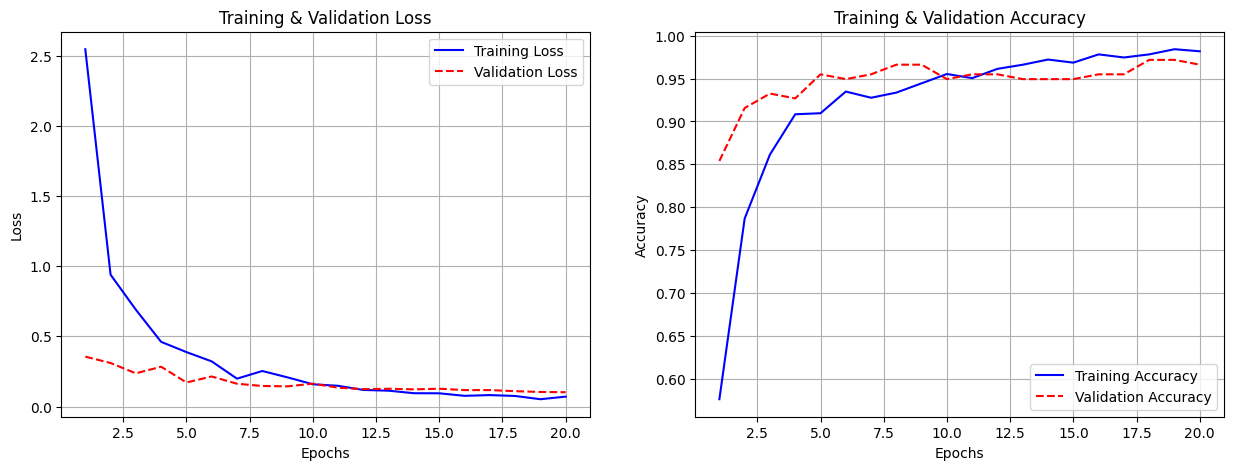

In [ ]:

# fit()이 돌려준 history에는 epoch마다 기록된 loss, accuracy, val_loss, val_accuracy가 들어 있습니다.
epochs = range(1, len(history.history['loss']) + 1)    # x축 값: 1, 2, 3, ... (epoch 번호)

plt.figure(figsize = (15, 5))    # 가로 15 × 세로 5 크기의 그림판 준비

plt.subplot(1, 2, 1)    # 1행 2열 중 왼쪽 그래프: 손실(Loss)
plt.plot(epochs, history.history['loss'], 'b-')    # 파란 실선: 훈련 데이터 기록
plt.plot(epochs, history.history['val_loss'], 'r--')    # 빨간 점선: 검증 데이터 기록
plt.title('Training & Validation Loss')    # 그래프 제목
plt.xlabel('Epochs')    # x축: 학습 반복 횟수
plt.ylabel('Loss')    # y축: 손실(작을수록 좋음)
plt.legend(['Training Loss', 'Validation Loss'])    # 범례(선 이름표) 표시
plt.grid()    # 격자 표시

plt.subplot(1, 2, 2)    # 1행 2열 중 오른쪽 그래프: 정확도(Accuracy)
plt.plot(epochs, history.history['accuracy'], 'b-')    # 파란 실선: 훈련 데이터 기록
plt.plot(epochs, history.history['val_accuracy'], 'r--')    # 빨간 점선: 검증 데이터 기록
plt.title('Training & Validation Accuracy')    # 그래프 제목
plt.xlabel('Epochs')    # x축: 학습 반복 횟수
plt.ylabel('Accuracy')    # y축: 정확도(클수록 좋음)
plt.legend(['Training Accuracy', 'Validation Accuracy'])    # 범례(선 이름표) 표시
plt.grid()    # 격자 표시

plt.show()    # 그래프 화면에 출력